# Kobe Bryant Shot Prediction

## Introduction

* **Dataset:** Kobe Bryant Shot Selection from Kaggle: [link](https://www.kaggle.com/competitions/kobe-bryant-shot-selection/data). It contains the shots Kobe Bryant took during his NBA career, with details like shot location, distance, type and time.
* **Goal:** predict whether a shot was made or missed (`shot_made_flag`).
* **Models:** K-Nearest Neighbors (KNN) and Logistic Regression.

#  1.Import Libraries

In [ ]:
# 1. Data Handling
import pandas as pd
import numpy as np

# 2. Visualization (EDA)
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# 3. Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 4. Data Splitting and Tuning
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

# 5. Machine Learning Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# 6. Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 7. Warnings
import warnings
warnings.filterwarnings("ignore")

#  2.Load Dataset

In [ ]:
df=pd.read_csv("/content/data.csv")

# 3.Data Understanding

In [ ]:
# Display the first 5 rows of the dataset
df.head()

,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,...,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
0,Jump Shot,Jump Shot,10,20000012,33.9723,167,72,-118.1028,10,1,...,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,1
1,Jump Shot,Jump Shot,12,20000012,34.0443,-157,0,-118.4268,10,1,...,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,2
2,Jump Shot,Jump Shot,35,20000012,33.9093,-101,135,-118.3708,7,1,...,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,3
3,Jump Shot,Jump Shot,43,20000012,33.8693,138,175,-118.1318,6,1,...,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,4
4,Driving Dunk Shot,Dunk,155,20000012,34.0443,0,0,-118.2698,6,2,...,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,5


In [ ]:
# Display the last 5 rows of the dataset
df.tail()

,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,...,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
30692,Jump Shot,Jump Shot,397,49900088,33.9963,1,48,-118.2688,6,4,...,2PT Field Goal,Center(C),In The Paint (Non-RA),Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-06-19,LAL vs. IND,IND,30693
30693,Tip Shot,Tip Shot,398,49900088,34.0443,0,0,-118.2698,6,4,...,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-06-19,LAL vs. IND,IND,30694
30694,Running Jump Shot,Jump Shot,426,49900088,33.8783,-134,166,-118.4038,3,4,...,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-06-19,LAL vs. IND,IND,30695
30695,Jump Shot,Jump Shot,448,49900088,33.7773,31,267,-118.2388,2,4,...,3PT Field Goal,Center(C),Above the Break 3,24+ ft.,1610612747,Los Angeles Lakers,2000-06-19,LAL vs. IND,IND,30696
30696,Jump Shot,Jump Shot,471,49900088,33.9723,1,72,-118.2688,0,4,...,2PT Field Goal,Center(C),In The Paint (Non-RA),Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-06-19,LAL vs. IND,IND,30697


In [ ]:
# Display column names as a list
df.columns.tolist()


['action_type',
 'combined_shot_type',
 'game_event_id',
 'game_id',
 'lat',
 'loc_x',
 'loc_y',
 'lon',
 'minutes_remaining',
 'period',
 'playoffs',
 'season',
 'seconds_remaining',
 'shot_distance',
 'shot_made_flag',
 'shot_type',
 'shot_zone_area',
 'shot_zone_basic',
 'shot_zone_range',
 'team_id',
 'team_name',
 'game_date',
 'matchup',
 'opponent',
 'shot_id']

In [ ]:
# This tells us how many samples and features we have.
print(" Shape:", df.shape)


 Shape: (30697, 25)


In [ ]:
# Data information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30697 entries, 0 to 30696
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   action_type         30697 non-null  object 
 1   combined_shot_type  30697 non-null  object 
 2   game_event_id       30697 non-null  int64  
 3   game_id             30697 non-null  int64  
 4   lat                 30697 non-null  float64
 5   loc_x               30697 non-null  int64  
 6   loc_y               30697 non-null  int64  
 7   lon                 30697 non-null  float64
 8   minutes_remaining   30697 non-null  int64  
 9   period              30697 non-null  int64  
 10  playoffs            30697 non-null  int64  
 11  season              30697 non-null  object 
 12  seconds_remaining   30697 non-null  int64  
 13  shot_distance       30697 non-null  int64  
 14  shot_made_flag      25697 non-null  float64
 15  shot_type           30697 non-null  object 
 16  shot

In [ ]:
# Statistical summary
df.describe()

,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,playoffs,seconds_remaining,shot_distance,shot_made_flag,team_id,shot_id
count,30697.000000,3.069700e+04,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,25697.000000,3.069700e+04,30697.000000
mean,249.190800,2.476407e+07,33.953192,7.110499,91.107535,-118.262690,4.885624,2.519432,0.146562,28.365085,13.437437,0.446161,1.610613e+09,15349.000000
std,150.003712,7.755175e+06,0.087791,110.124578,87.791361,0.110125,3.449897,1.153665,0.353674,17.478949,9.374189,0.497103,0.000000e+00,8861.604943
min,2.000000,2.000001e+07,33.253300,-250.000000,-44.000000,-118.519800,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.610613e+09,1.000000
25%,110.000000,2.050008e+07,33.884300,-68.000000,4.000000,-118.337800,2.000000,1.000000,0.000000,13.000000,5.000000,0.000000,1.610613e+09,7675.000000
50%,253.000000,2.090035e+07,33.970300,0.000000,74.000000,-118.269800,5.000000,3.000000,0.000000,28.000000,15.000000,0.000000,1.610613e+09,15349.000000
75%,368.000000,2.960047e+07,34.040300,95.000000,160.000000,-118.174800,8.000000,3.000000,0.000000,43.000000,21.000000,1.000000,1.610613e+09,23023.000000
max,659.000000,4.990009e+07,34.088300,248.000000,791.000000,-118.021800,11.000000,7.000000,1.000000,59.000000,79.000000,1.000000,1.610613e+09,30697.000000


# 4.Data Cleaning and Preprocessing




* check the dataset for missing values, duplicates, inconsistent data, and prepare the features for analysis.
This step ensures the data is clean, reliable, and ready for deeper exploration and modeling.

In [ ]:
# Missing Values Analysis
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().sum() / len(df)) * 100
})

display(missing.round(2))

,Missing Values,Missing Percentage (%)
action_type,0,0.00
combined_shot_type,0,0.00
game_event_id,0,0.00
game_id,0,0.00
lat,0,0.00
loc_x,0,0.00
loc_y,0,0.00
lon,0,0.00
minutes_remaining,0,0.00
period,0,0.00


In [ ]:
# Check duplicate rows
print("Number of Duplicate Rows:", df.duplicated().sum())

# Duplicate Percentage
print("Duplicate Percentage:", round(df.duplicated().mean() * 100, 2), "%")

Number of Duplicate Rows: 0
Duplicate Percentage: 0.0 %


In [ ]:
# Number of Unique Values
unique_values = pd.DataFrame({
    "Unique Values": df.nunique(),
})

display(unique_values.sort_values("Unique Values"))

,Unique Values
team_name,1
team_id,1
shot_type,2
shot_made_flag,2
playoffs,2
shot_zone_range,5
shot_zone_area,6
combined_shot_type,6
period,7
shot_zone_basic,7


In [ ]:
# Check constant columns
print("team_name:", df["team_name"].unique())
print("team_id:", df["team_id"].unique())

team_name: ['Los Angeles Lakers']
team_id: [1610612747]


In [ ]:
# Drop constant columns
df.drop(columns=["team_name", "team_id"], inplace=True)

print("Updated Shape:", df.shape)

Updated Shape: (30697, 23)


In [ ]:
cols = ["minutes_remaining", "seconds_remaining", "period", "shot_distance"]

display(df[cols].describe().T)



,count,mean,std,min,25%,50%,75%,max
minutes_remaining,30697.0,4.885624,3.449897,0.0,2.0,5.0,8.0,11.0
seconds_remaining,30697.0,28.365085,17.478949,0.0,13.0,28.0,43.0,59.0
period,30697.0,2.519432,1.153665,1.0,1.0,3.0,3.0,7.0
shot_distance,30697.0,13.437437,9.374189,0.0,5.0,15.0,21.0,79.0



* Check numerical columns for invalid or unusual values.
* minutes_remaining and seconds_remaining are within their expected ranges.
* The maximum period is 7, which may represent overtime periods.
*The maximum shot distance is 79 feet, which is unusually high but not necessarily incorrect.
* No values are modified or removed at this stage.



In [ ]:
print(df["period"].value_counts().sort_index())

period
1    8048
2    6718
3    8296
4    7260
5     330
6      38
7       7
Name: count, dtype: int64


* Most shots occurred during the four regular periods.
*  Periods 5, 6, and 7 represent overtime periods.
* These values are valid and should not be removed as outliers.


In [ ]:

# Calculate the first and third quartiles
Q1 = df["shot_distance"].quantile(0.25)
Q3 = df["shot_distance"].quantile(0.75)

# Calculate the Interquartile Range (IQR)
IQR = Q3 - Q1

# Calculate the lower and upper bounds for potential outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Display the results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


Q1: 5.0
Q3: 21.0
IQR: 16.0
Lower Bound: -19.0
Upper Bound: 45.0


In [ ]:
# Count potential outliers above the upper bound
outliers = df[df["shot_distance"] > upper_bound]

print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:", round(len(outliers) / len(df) * 100, 2), "%")

Number of potential outliers: 68
Percentage of potential outliers: 0.22 %


In [ ]:
# Display the 10 largest shot distances
display(df.nlargest(10, "shot_distance")[["shot_distance", "shot_zone_basic", "shot_zone_range"]])

,shot_distance,shot_zone_basic,shot_zone_range
29122,79,Backcourt,Back Court Shot
27991,77,Backcourt,Back Court Shot
6650,74,Backcourt,Back Court Shot
13026,74,Backcourt,Back Court Shot
29137,74,Backcourt,Back Court Shot
27507,71,Backcourt,Back Court Shot
1073,70,Backcourt,Back Court Shot
7526,70,Backcourt,Back Court Shot
20498,69,Backcourt,Back Court Shot
3715,68,Backcourt,Back Court Shot



* Outlier Analysis Conclusion:
* The IQR method identified 68 potential outliers (0.22%) in shot_distance.
* These shots are classified as Backcourt shots.
* Since extreme distances may represent valid basketball shots,
* no values were removed or modified.


In [ ]:
# Display all remaining column names
print(df.columns.tolist())

['action_type', 'combined_shot_type', 'game_event_id', 'game_id', 'lat', 'loc_x', 'loc_y', 'lon', 'minutes_remaining', 'period', 'playoffs', 'season', 'seconds_remaining', 'shot_distance', 'shot_made_flag', 'shot_type', 'shot_zone_area', 'shot_zone_basic', 'shot_zone_range', 'game_date', 'matchup', 'opponent', 'shot_id']


In [ ]:
# Check the number of unique values in identifier columns
columns_to_check = [
    "game_event_id",
    "game_id",
    "shot_id",
    "game_date",
    "matchup",
    "opponent",
    "lon"
]

for col in columns_to_check:
    print(f"{col}: {df[col].nunique()} unique values")

game_event_id: 620 unique values
game_id: 1559 unique values
shot_id: 30697 unique values
game_date: 1559 unique values
matchup: 74 unique values
opponent: 33 unique values
lon: 489 unique values


In [ ]:
# Remove identifier columns that are not directly useful for prediction
df.drop(columns=["shot_id", "game_event_id", "game_id"], inplace=True)

# Check the updated dataset
print("Updated Shape:", df.shape)
print(df.columns.tolist())

Updated Shape: (30697, 20)
['action_type', 'combined_shot_type', 'lat', 'loc_x', 'loc_y', 'lon', 'minutes_remaining', 'period', 'playoffs', 'season', 'seconds_remaining', 'shot_distance', 'shot_made_flag', 'shot_type', 'shot_zone_area', 'shot_zone_basic', 'shot_zone_range', 'game_date', 'matchup', 'opponent']


In [ ]:
# Check correlations between numerical features
numeric_cols = [
    "lat", "lon", "loc_x", "loc_y", "shot_distance",
    "minutes_remaining", "seconds_remaining", "period"
]

correlation_matrix = df[numeric_cols].corr()

display(correlation_matrix.round(2))

,lat,lon,loc_x,loc_y,shot_distance,minutes_remaining,seconds_remaining,period
lat,1.00,0.02,0.02,-1.00,-0.82,0.07,0.05,-0.04
lon,0.02,1.00,1.00,-0.02,0.02,0.01,0.00,-0.03
loc_x,0.02,1.00,1.00,-0.02,0.02,0.01,0.00,-0.03
loc_y,-1.00,-0.02,-0.02,1.00,0.82,-0.07,-0.05,0.04
shot_distance,-0.82,0.02,0.02,0.82,1.00,-0.06,-0.05,0.05
minutes_remaining,0.07,0.01,0.01,-0.07,-0.06,1.00,0.03,-0.04
seconds_remaining,0.05,0.00,0.00,-0.05,-0.05,0.03,1.00,0.01
period,-0.04,-0.03,-0.03,0.04,0.05,-0.04,0.01,1.00


In [ ]:
# Remove highly redundant coordinate columns
df.drop(columns=["lat", "lon"], inplace=True)

# Check the updated dataset
print("Updated Shape:", df.shape)
print(df.columns.tolist())

Updated Shape: (30697, 18)
['action_type', 'combined_shot_type', 'loc_x', 'loc_y', 'minutes_remaining', 'period', 'playoffs', 'season', 'seconds_remaining', 'shot_distance', 'shot_made_flag', 'shot_type', 'shot_zone_area', 'shot_zone_basic', 'shot_zone_range', 'game_date', 'matchup', 'opponent']


 * Remove redundant coordinate columns (lat and lon).

* lat and lon are the same as loc_y and loc_x (correlation = 1.00), so we keep loc_x and loc_y only.

#  5. Exploratory Data Analysis (EDA)


### 5.1 Univariate Analysis

1. Target Variable Distribution

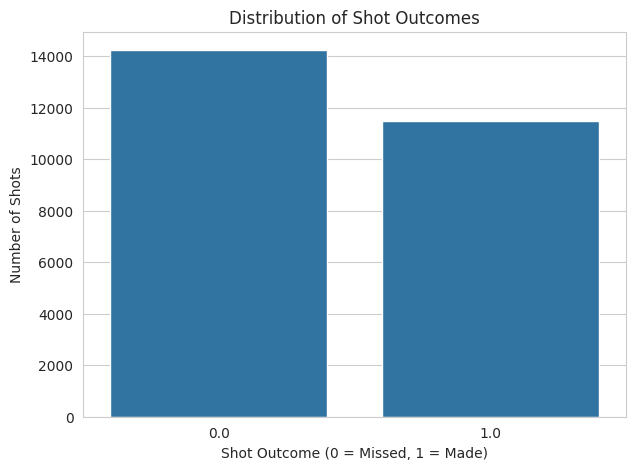

In [ ]:
# * Visualize the distribution of shot outcomes
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="shot_made_flag")

plt.title("Distribution of Shot Outcomes")
plt.xlabel("Shot Outcome (0 = Missed, 1 = Made)")
plt.ylabel("Number of Shots")

plt.show()

* The plot shows that missed shots are more frequent than successful shots, indicating a slight class imbalance in the target variable.

2. Shot Distance Distribution

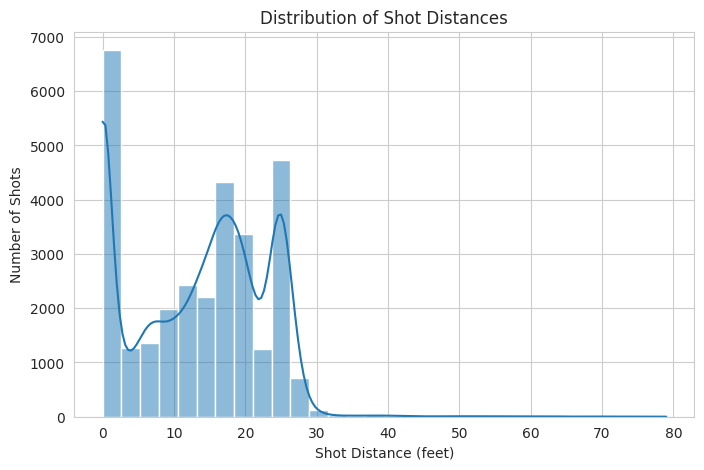

In [ ]:
# * Visualize the distribution of shot distances
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="shot_distance", bins=30, kde=True)

plt.title("Distribution of Shot Distances")
plt.xlabel("Shot Distance (feet)")
plt.ylabel("Number of Shots")

plt.show()

* Most shots are taken from close distances, especially near the basket. The number of shots generally decreases as distance increases, with very few shots taken from beyond 30 feet.


3. Shot Types Distribution

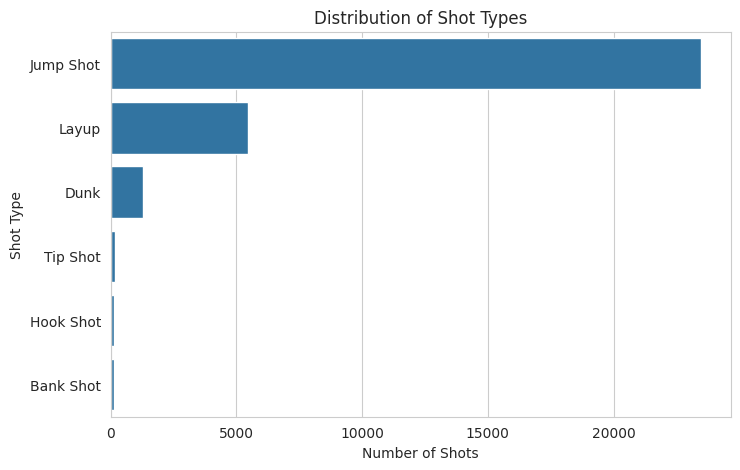

In [ ]:
# * Visualize the distribution of shot types
plt.figure(figsize=(8, 5))

sns.countplot(data=df, y="combined_shot_type",
              order=df["combined_shot_type"].value_counts().index)

plt.title("Distribution of Shot Types")
plt.xlabel("Number of Shots")
plt.ylabel("Shot Type")

plt.show()

* Jump shots are the most common shot type, followed by layups, while dunks are much less frequent. This shows that Kobe Bryant relied heavily on jump shots compared to other shot types.


4. Shot Zone Distribution

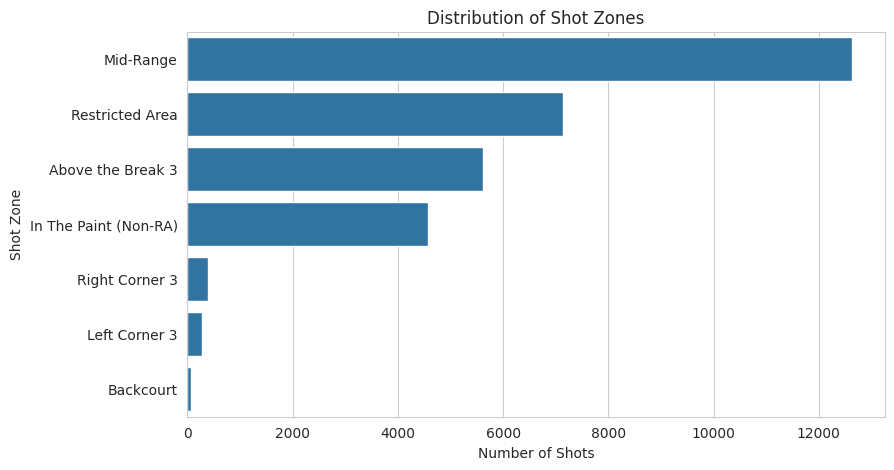

In [ ]:
# * Visualize the distribution of shot zones
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    y="shot_zone_basic",
    order=df["shot_zone_basic"].value_counts().index
)

plt.title("Distribution of Shot Zones")
plt.xlabel("Number of Shots")
plt.ylabel("Shot Zone")

plt.show()

* Mid-Range is the most common shot zone, followed by Restricted Area and Above the Break 3. Other zones have fewer shots.


5. Shot Type Distribution (2PT vs 3PT)

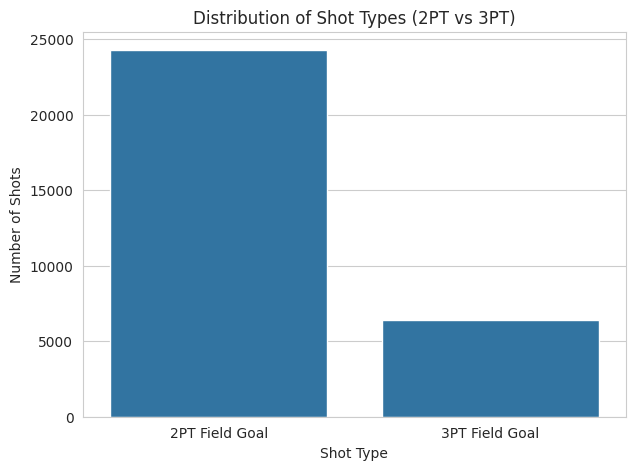

In [ ]:
# * Visualize the distribution of shot types by point value
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="shot_type")

plt.title("Distribution of Shot Types (2PT vs 3PT)")
plt.xlabel("Shot Type")
plt.ylabel("Number of Shots")

plt.show()

* 2PT shots are much more common than 3PT shots, with approximately 25,000 and 6,000 attempts, respectively.

6. Shot Distribution by Period

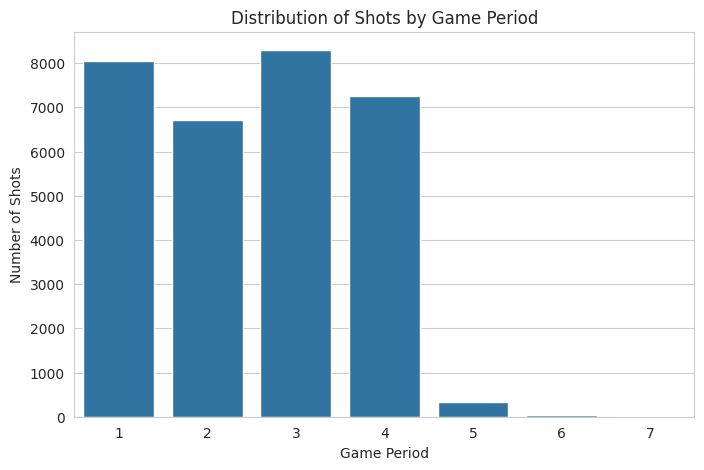

In [ ]:
# * Visualize the distribution of shots by game period
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="period")

plt.title("Distribution of Shots by Game Period")
plt.xlabel("Game Period")
plt.ylabel("Number of Shots")

plt.show()

* Most shots occur in periods 1–4, while overtime periods have significantly fewer shots.


### 5.2 Bivariate Analysis

In [ ]:
# Create a copy of the dataset containing only shots with known outcomes
df_labeled = df.dropna(subset=["shot_made_flag"])

1. Shot Type vs Shot Outcome

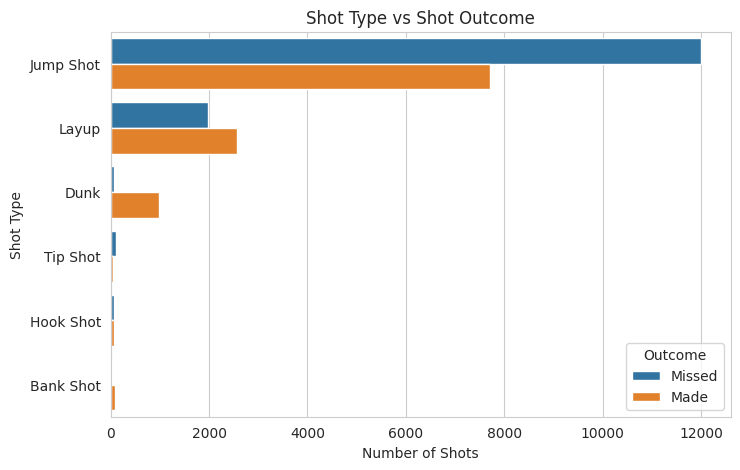

In [ ]:
# * Visualize shot outcomes for each shot type
plt.figure(figsize=(8, 5))

sns.countplot(data=df_labeled, y="combined_shot_type", hue="shot_made_flag",
              order=df_labeled["combined_shot_type"].value_counts().index)

plt.title("Shot Type vs Shot Outcome")
plt.xlabel("Number of Shots")
plt.ylabel("Shot Type")
plt.legend(title="Outcome", labels=["Missed", "Made"], loc="lower right")

plt.show()

* Jump shots have more missed shots than made shots, while dunks and layups are made more often, showing that shot type affects shot success.

2. Shot Distance vs Shot Outcome

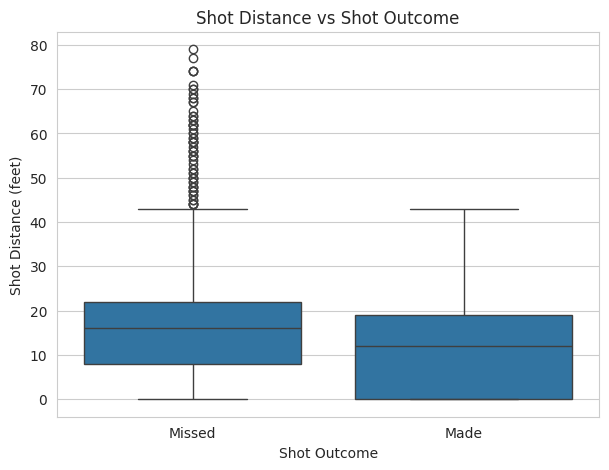

In [ ]:
# * Compare shot distances for missed and made shots
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_labeled, x="shot_made_flag", y="shot_distance")

plt.title("Shot Distance vs Shot Outcome")
plt.xlabel("Shot Outcome")
plt.ylabel("Shot Distance (feet)")
plt.xticks([0, 1], ["Missed", "Made"])

plt.show()

* Made shots are usually taken from shorter distances than missed shots, showing that the closer the shot is to the basket, the more likely it is to be made.

3. Shot Type (2PT vs 3PT) vs Shot Outcome

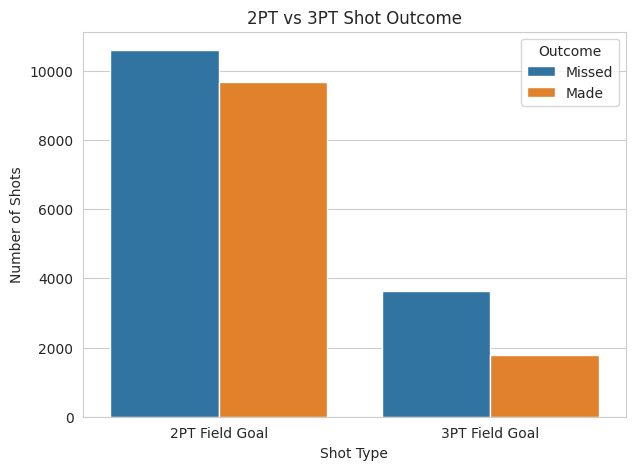

In [ ]:
# * Visualize shot outcomes for 2PT and 3PT shots
plt.figure(figsize=(7, 5))

sns.countplot(data=df_labeled, x="shot_type", hue="shot_made_flag")

plt.title("2PT vs 3PT Shot Outcome")
plt.xlabel("Shot Type")
plt.ylabel("Number of Shots")
plt.legend(title="Outcome", labels=["Missed", "Made"], loc="upper right")

plt.show()

* 2PT shots are made almost half of the time, while only about one third of 3PT shots are made, since 3PT shots are taken from farther away and are harder to score.

4. Game Period vs Shot Outcome

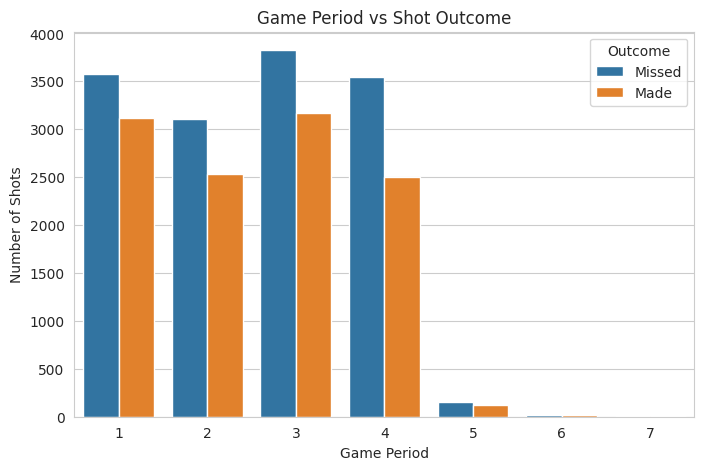

In [ ]:
# * Visualize shot outcomes for each game period
plt.figure(figsize=(8, 5))

sns.countplot(data=df_labeled, x="period", hue="shot_made_flag")

plt.title("Game Period vs Shot Outcome")
plt.xlabel("Game Period")
plt.ylabel("Number of Shots")
plt.legend(title="Outcome", labels=["Missed", "Made"], loc="upper right")

plt.show()

* Missed shots are higher than made shots in every period, and the gap is largest in the 4th period, possibly due to pressure at the end of the game.

5. Playoffs vs Shot Outcome

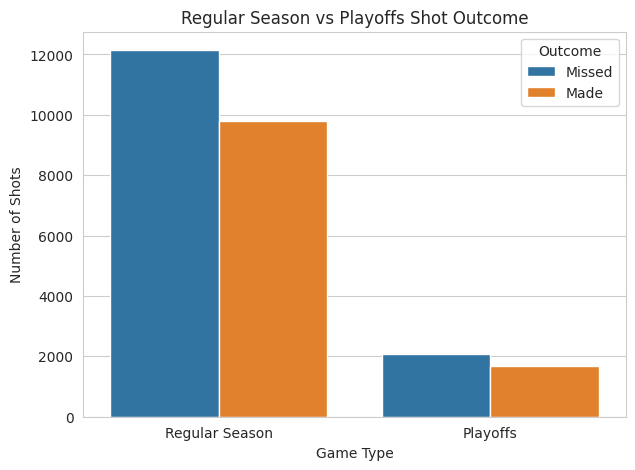

In [ ]:
# * Visualize shot outcomes in regular season and playoff games
plt.figure(figsize=(7, 5))

sns.countplot(data=df_labeled, x="playoffs", hue="shot_made_flag")

plt.title("Regular Season vs Playoffs Shot Outcome")
plt.xlabel("Game Type")
plt.ylabel("Number of Shots")
plt.xticks([0, 1], ["Regular Season", "Playoffs"])
plt.legend(title="Outcome", labels=["Missed", "Made"], loc="upper right")

plt.show()

* Most shots were taken in regular season games, but the success rate is almost the same in regular season and playoffs, so game type has little effect on shot success.

6. Shot Zone vs Shot Outcome

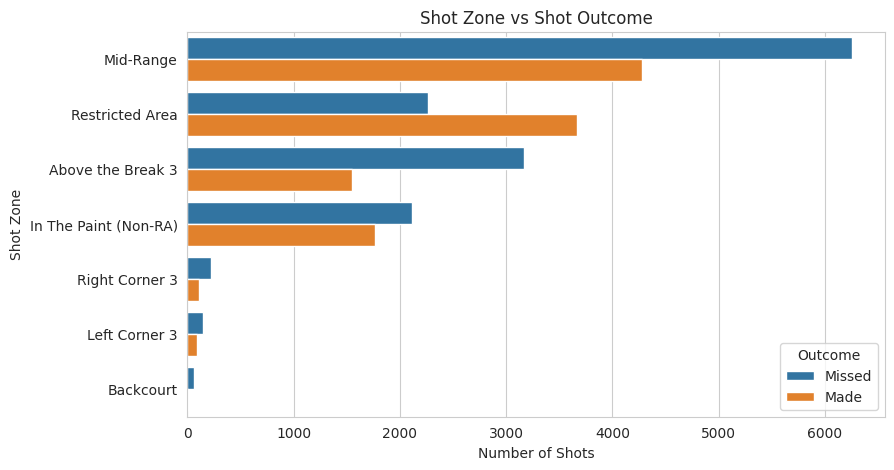

In [ ]:
# * Visualize shot outcomes for each shot zone
plt.figure(figsize=(9, 5))

sns.countplot(data=df_labeled, y="shot_zone_basic", hue="shot_made_flag",
              order=df_labeled["shot_zone_basic"].value_counts().index)

plt.title("Shot Zone vs Shot Outcome")
plt.xlabel("Number of Shots")
plt.ylabel("Shot Zone")
plt.legend(title="Outcome", labels=["Missed", "Made"], loc="lower right")

plt.show()

* The Restricted Area is the only zone with more made shots than missed shots, while Mid-Range is the most common zone and the three-point zones (Above the Break 3 and Corner 3) have far more misses, showing that shots closer to the basket are more successful.

7. Season vs Shot Outcome

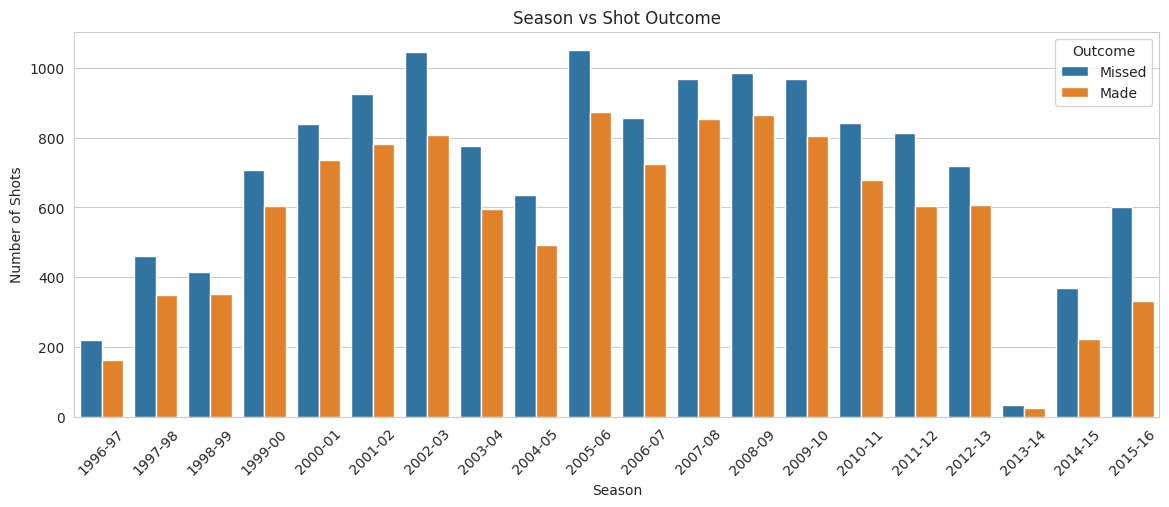

In [ ]:
# * Visualize shot outcomes for each season of Kobe's career
plt.figure(figsize=(14, 5))

sns.countplot(data=df_labeled, x="season", hue="shot_made_flag",
              order=sorted(df_labeled["season"].unique()))

plt.title("Season vs Shot Outcome")
plt.xlabel("Season")
plt.ylabel("Number of Shots")
plt.xticks(rotation=45)
plt.legend(title="Outcome", labels=["Missed", "Made"], loc="upper right")

plt.show()

* Missed shots are higher than made shots in every season, and the gap becomes much larger in Kobe's final seasons (2014-15 and 2015-16), showing a decline in his shooting performance near the end of his career.

### 5.3 Multivariate Analysis

1. Shot Location vs Shot Outcome (loc_x, loc_y, shot_made_flag)

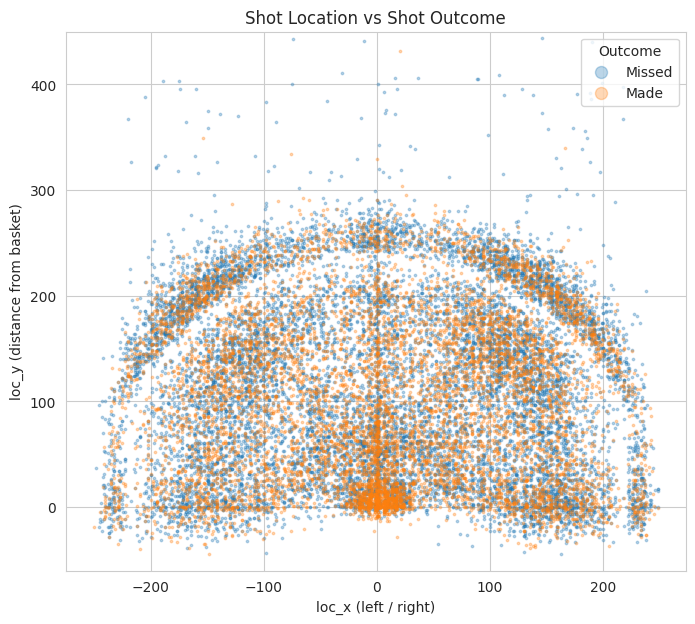

In [ ]:
# * Visualize the location of each shot on the court, colored by shot outcome
plt.figure(figsize=(8, 7))

missed = df_labeled[df_labeled["shot_made_flag"] == 0]
made = df_labeled[df_labeled["shot_made_flag"] == 1]

plt.scatter(missed["loc_x"], missed["loc_y"], s=3, alpha=0.3, color="tab:blue", label="Missed")
plt.scatter(made["loc_x"], made["loc_y"], s=3, alpha=0.3, color="tab:orange", label="Made")

plt.title("Shot Location vs Shot Outcome")
plt.xlabel("loc_x (left / right)")
plt.ylabel("loc_y (distance from basket)")
plt.ylim(-60, 450)
plt.legend(title="Outcome", markerscale=5, loc="upper right")

plt.show()

* Plotting loc_x and loc_y draws the shape of the court: made shots are concentrated right next to the basket, while missed shots dominate along the three-point line and at long distances.

2. Shot Type and Shot Distance vs Shot Outcome

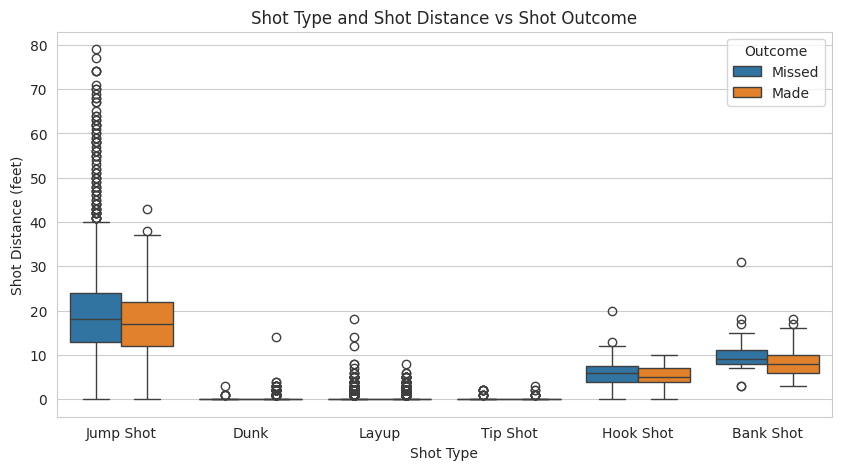

In [ ]:
# * Compare shot distances of missed and made shots for each shot type
plt.figure(figsize=(10, 5))

ax = sns.boxplot(data=df_labeled, x="combined_shot_type", y="shot_distance", hue="shot_made_flag")

plt.title("Shot Type and Shot Distance vs Shot Outcome")
plt.xlabel("Shot Type")
plt.ylabel("Shot Distance (feet)")

handles, _ = ax.get_legend_handles_labels()
plt.legend(handles, ["Missed", "Made"], title="Outcome", loc="upper right")

plt.show()

* For jump shots, hook shots and bank shots, made shots are slightly closer to the basket than missed shots, while dunks, layups and tip shots are taken right at the basket, so both shot type and distance affect shot success.


* Note: Dunks, layups and tip shots are almost always taken right at the basket, so any shot a few feet away appears as an outlier. These are real shots, so we keep them.

3. Correlation Heatmap (Numerical Features and Target)

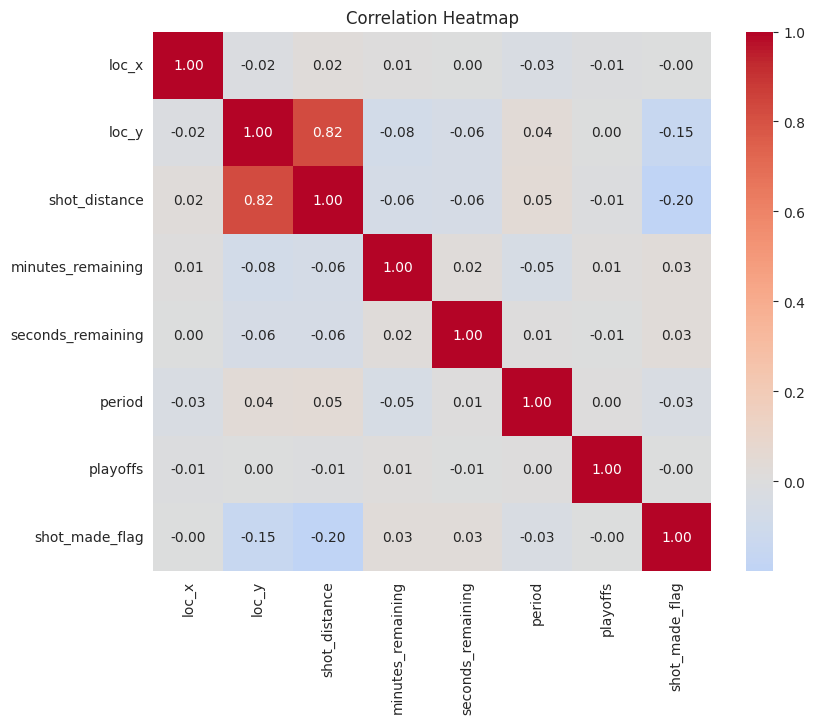

In [ ]:
# * Visualize the correlation between numerical features and the target
corr_cols = ["loc_x", "loc_y", "shot_distance", "minutes_remaining",
             "seconds_remaining", "period", "playoffs", "shot_made_flag"]

plt.figure(figsize=(9, 7))

sns.heatmap(df_labeled[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Correlation Heatmap")

plt.show()

* shot_distance has the strongest correlation with shot_made_flag (-0.20), followed by loc_y (-0.15), meaning longer shots are less likely to be made. loc_y and shot_distance are also highly correlated with each other (0.82), while the other features have almost no relationship with the target.

## 6.Data Preprocessing

* Prepare the data for training: remove unknown targets, create new features, choose X and y, check imbalance, split, encode and scale.

1. Remove Shots Without a Known Outcome

In [ ]:
# Keep only the shots with a known outcome (shot_made_flag is not missing)
df_model = df.dropna(subset=["shot_made_flag"]).copy()

print("Shape before:", df.shape)
print("Shape after :", df_model.shape)
print("Remaining missing values:", df_model.isnull().sum().sum())

Shape before: (30697, 18)
Shape after : (25697, 18)
Remaining missing values: 0


* The 5,000 shots without a result can't be used for training or testing because we don't know the real answer, so we only use the 25,697 labeled shots.

2. Feature Engineering

In [ ]:
# Create new features from existing columns
# home: 1 if the game was played at home ("LAL vs. XXX"), 0 if away ("LAL @ XXX")
df_model["home"] = df_model["matchup"].str.contains("vs.", regex=False).astype(int)

# season_start: the first year of the season, e.g. "2000-01" -> 2000
df_model["season_start"] = df_model["season"].str[:4].astype(int)

# time_remaining: total seconds left in the period
df_model["time_remaining"] = df_model["minutes_remaining"] * 60 + df_model["seconds_remaining"]

display(df_model[["matchup", "home", "season", "season_start",
                  "minutes_remaining", "seconds_remaining", "time_remaining"]].head())

,matchup,home,season,season_start,minutes_remaining,seconds_remaining,time_remaining
1,LAL @ POR,0,2000-01,2000,10,22,622
2,LAL @ POR,0,2000-01,2000,7,45,465
3,LAL @ POR,0,2000-01,2000,6,52,412
4,LAL @ POR,0,2000-01,2000,6,19,379
5,LAL @ POR,0,2000-01,2000,9,32,572


* home: 1 for home games and 0 for away games (taken from matchup).
* season_start: the season as a number (2000-01 → 2000).
* time_remaining: minutes and seconds combined into seconds.

3. Select Features (X) and Target (y) — Data Leakage Check

In [ ]:
# Define the target and the feature columns
target = "shot_made_flag"

numeric_features = ["loc_x", "loc_y", "shot_distance", "time_remaining",
                    "period", "playoffs", "home", "season_start"]

categorical_features = ["action_type", "combined_shot_type", "shot_type",
                        "shot_zone_area", "shot_zone_basic", "shot_zone_range", "opponent"]

X = df_model[numeric_features + categorical_features]
y = df_model[target].astype(int)

# Make sure the target is not inside X
print("Target in X:", target in X.columns)
print("X shape:", X.shape)
print("y shape:", y.shape)

Target in X: False
X shape: (25697, 15)
y shape: (25697,)


* No data leakage: the target is not in X, and all features are known before the shot is taken.
* game_date, matchup and season were removed because the new features already cover them.

4. Check Class Imbalance

In [ ]:
# Check the balance between missed and made shots
class_counts = y.value_counts()
class_percent = y.value_counts(normalize=True) * 100

display(pd.DataFrame({"Count": class_counts, "Percentage (%)": class_percent.round(2)})
        .rename(index={0: "Missed (0)", 1: "Made (1)"}))

,Count,Percentage (%)
shot_made_flag,,
Missed (0),14232,55.38
Made (1),11465,44.62


* The data has a slight imbalance (55% missed, 45% made), so no resampling is needed. We use stratify when splitting to keep the same ratio.

5. Train-Test Split

In [ ]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("\nMade percentage in train:", round(y_train.mean() * 100, 2), "%")
print("Made percentage in test :", round(y_test.mean() * 100, 2), "%")

Training set: (20557, 15)
Testing set : (5140, 15)

Made percentage in train: 44.62 %
Made percentage in test : 44.61 %


* Both train and test sets have the same percentage of made shots (44.6%).

6. Encoding and Feature Scaling

In [ ]:
# Build the preprocessing step
# Numerical features -> StandardScaler (mean = 0, std = 1)
# Categorical features -> OneHotEncoder (one 0/1 column for each category)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Fit on the training set only, then check the result
preprocessor.fit(X_train)
print("Number of features after encoding:", len(preprocessor.get_feature_names_out()))

Number of features after encoding: 122


* OneHotEncoder turns categorical columns into 0/1 columns, and StandardScaler puts numbers on the same scale (very important for KNN because it uses distances).
* The scaler and encoder are inside a Pipeline, so they learn from the training data only.

# 7. Model Training

1. K-Nearest Neighbors (KNN)

In [ ]:
# Train a KNN model with the default settings (k = 5)
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['loc_x', 'loc_y',
                                                   'shot_distance',
                                                   'time_remaining', 'period',
                                                   'playoffs', 'home',
                                                   'season_start']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['action_type',
                                                   'combined_shot_type',
                                                   'shot_type',
                                                   'shot_zone_area',
                                                   'shot_zone_basic',
                                                   'shot_zone_range',
                                                   'opponent'])])),
                ('model', KNeighborsClassifier())])

2. Logistic Regression

In [ ]:
# Train a Logistic Regression model with the default settings
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

lr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['loc_x', 'loc_y',
                                                   'shot_distance',
                                                   'time_remaining', 'period',
                                                   'playoffs', 'home',
                                                   'season_start']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['action_type',
                                                   'combined_shot_type',
                                                   'shot_type',
                                                   'shot_zone_area',
                                                   'shot_zone_basic',
                                                   'shot_zone_range',
                                                   'opponent'])])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

* Both models are trained with default settings first, then improved later with Grid Search.

# 8. Model Evaluation

In [ ]:
# Helper function to evaluate a model on the test set
def evaluate_model(name, model):
    y_pred = model.predict(X_test)

    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["Missed", "Made"]))

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Missed", "Made"], yticklabels=["Missed", "Made"])
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    }

1. KNN (Baseline)

===== KNN (k=5) =====
              precision    recall  f1-score   support

      Missed       0.63      0.71      0.67      2847
        Made       0.58      0.49      0.53      2293

    accuracy                           0.61      5140
   macro avg       0.60      0.60      0.60      5140
weighted avg       0.61      0.61      0.61      5140



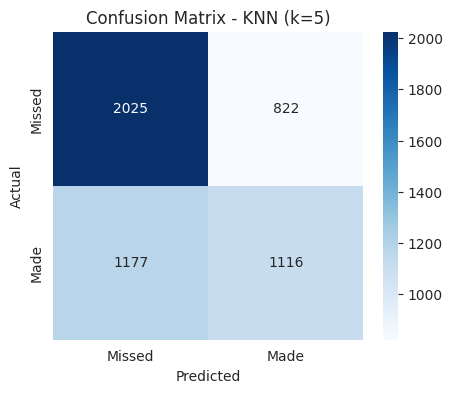

In [ ]:
knn_results = evaluate_model("KNN (k=5)", knn_model)

* KNN (k=5) reaches 61% accuracy, but it makes many mistakes on both classes, because 5 neighbors are too few for this noisy data.

2. Logistic Regression (Baseline)

===== Logistic Regression =====
              precision    recall  f1-score   support

      Missed       0.66      0.85      0.74      2847
        Made       0.71      0.46      0.56      2293

    accuracy                           0.68      5140
   macro avg       0.69      0.65      0.65      5140
weighted avg       0.68      0.68      0.66      5140



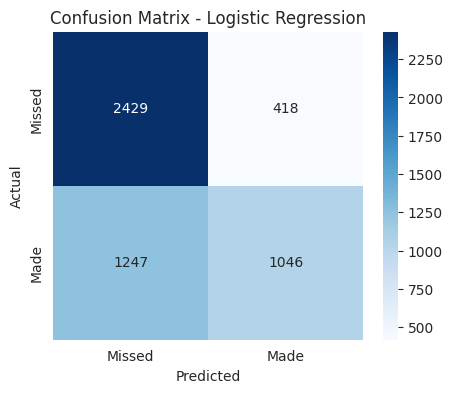

In [ ]:
lr_results = evaluate_model("Logistic Regression", lr_model)

* Logistic Regression reaches 68% accuracy. It predicts missed shots very well (85%) but misses more than half of the made shots.

3. Baseline Comparison

In [ ]:
# * Compare the two baseline models
baseline_comparison = pd.DataFrame([knn_results, lr_results]).set_index("Model")

display(baseline_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score
Model,,,,
KNN (k=5),0.6111,0.5759,0.4867,0.5275
Logistic Regression,0.6761,0.7145,0.4562,0.5568


* Logistic Regression is better than KNN in accuracy, precision and F1 score.
* Both models beat the simple guess of always predicting "Missed" (55%).

# 9. Hyperparameter Tuning with Grid Search

* Grid Search tries different hyperparameters with 5-fold cross-validation on the training set only, and picks the best ones.

In [ ]:
# 5-fold stratified cross-validation (keeps the 55/45 ratio in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

1. Tuning KNN

In [ ]:
# Hyperparameters to try for KNN
knn_params = {
    "model__n_neighbors": [5, 15, 25, 51, 75, 101],   # number of neighbors (k)
    "model__weights": ["uniform", "distance"],        # equal vote or closer neighbors count more
    "model__p": [1, 2]                                # 1 = Manhattan distance, 2 = Euclidean distance
}

knn_grid = GridSearchCV(knn_model, knn_params, cv=cv, scoring="accuracy", n_jobs=-1)
knn_grid.fit(X_train, y_train)

print("Best parameters:", knn_grid.best_params_)
print("Best CV accuracy:", round(knn_grid.best_score_, 4))

Best parameters: {'model__n_neighbors': 75, 'model__p': 1, 'model__weights': 'distance'}
Best CV accuracy: 0.6556


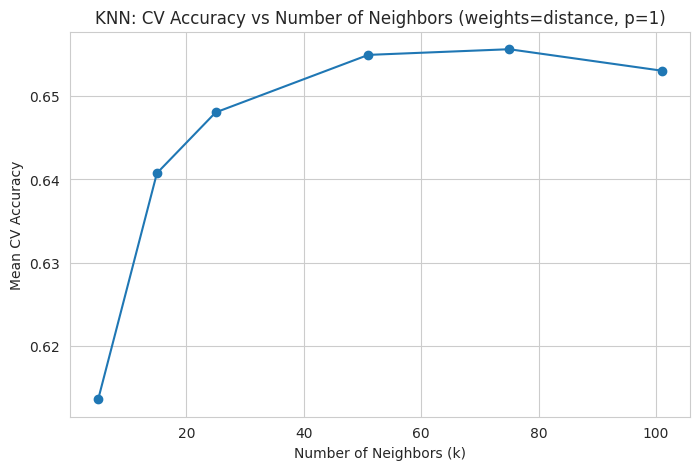

In [ ]:
# Visualize how the CV accuracy changes with k
knn_cv_results = pd.DataFrame(knn_grid.cv_results_)
best_weights = knn_grid.best_params_["model__weights"]
best_p = knn_grid.best_params_["model__p"]

k_curve = knn_cv_results[(knn_cv_results["param_model__weights"] == best_weights) &
                         (knn_cv_results["param_model__p"] == best_p)]

plt.figure(figsize=(8, 5))

plt.plot(k_curve["param_model__n_neighbors"].astype(int), k_curve["mean_test_score"], marker="o")

plt.title(f"KNN: CV Accuracy vs Number of Neighbors (weights={best_weights}, p={best_p})")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean CV Accuracy")

plt.show()

* The best KNN uses k=75. Accuracy increases quickly until about k=50 and then stays almost the same.

2. Tuning Logistic Regression

In [ ]:
# Hyperparameters to try for Logistic Regression
lr_params = {
    "model__C": [0.01, 0.1, 1, 10],                 # regularization strength (smaller = stronger)
    "model__class_weight": [None, "balanced"]       # handle the slight class imbalance
}

lr_grid = GridSearchCV(lr_model, lr_params, cv=cv, scoring="accuracy", n_jobs=-1)
lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV accuracy:", round(lr_grid.best_score_, 4))

Best parameters: {'model__C': 0.1, 'model__class_weight': None}
Best CV accuracy: 0.6834


* The best Logistic Regression uses C=0.1 without class weights, so balancing the classes did not help.

3. Evaluation of the Tuned Models

===== KNN (Tuned) =====
              precision    recall  f1-score   support

      Missed       0.63      0.90      0.74      2847
        Made       0.74      0.36      0.48      2293

    accuracy                           0.66      5140
   macro avg       0.69      0.63      0.61      5140
weighted avg       0.68      0.66      0.63      5140



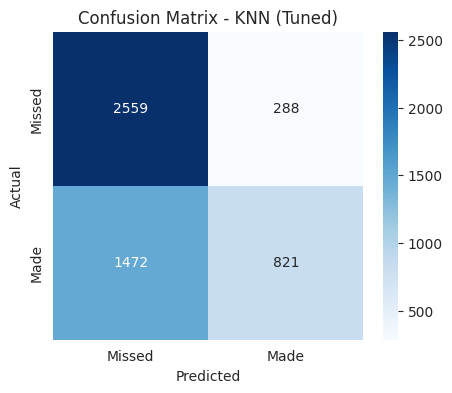

In [ ]:
knn_tuned_results = evaluate_model("KNN (Tuned)", knn_grid.best_estimator_)

===== Logistic Regression (Tuned) =====
              precision    recall  f1-score   support

      Missed       0.66      0.85      0.74      2847
        Made       0.71      0.46      0.56      2293

    accuracy                           0.68      5140
   macro avg       0.69      0.66      0.65      5140
weighted avg       0.68      0.68      0.66      5140



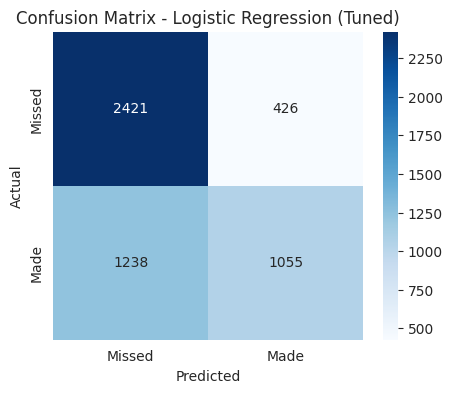

In [ ]:
lr_tuned_results = evaluate_model("Logistic Regression (Tuned)", lr_grid.best_estimator_)

4. Final Comparison

In [ ]:
# Compare all models before and after tuning
final_comparison = pd.DataFrame([knn_results, knn_tuned_results,
                                 lr_results, lr_tuned_results]).set_index("Model")

display(final_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score
Model,,,,
KNN (k=5),0.6111,0.5759,0.4867,0.5275
KNN (Tuned),0.6576,0.7403,0.3580,0.4827
Logistic Regression,0.6761,0.7145,0.4562,0.5568
Logistic Regression (Tuned),0.6763,0.7124,0.4601,0.5591


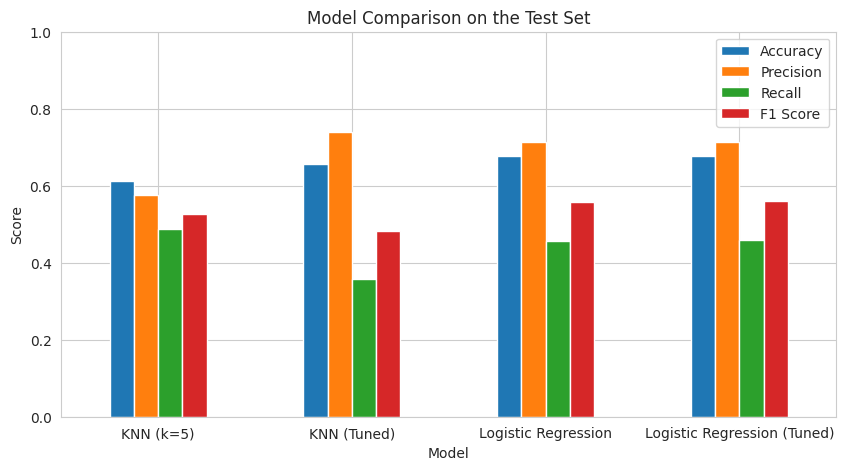

In [ ]:
# Visualize the comparison
final_comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Model Comparison on the Test Set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="upper right")

plt.show()

* Grid Search improved KNN from 61% to 66%, but barely changed Logistic Regression (68%).
* Logistic Regression is the best model overall, and about 68% accuracy is normal for this dataset.

5. Which Features Matter Most? (Logistic Regression Coefficients)

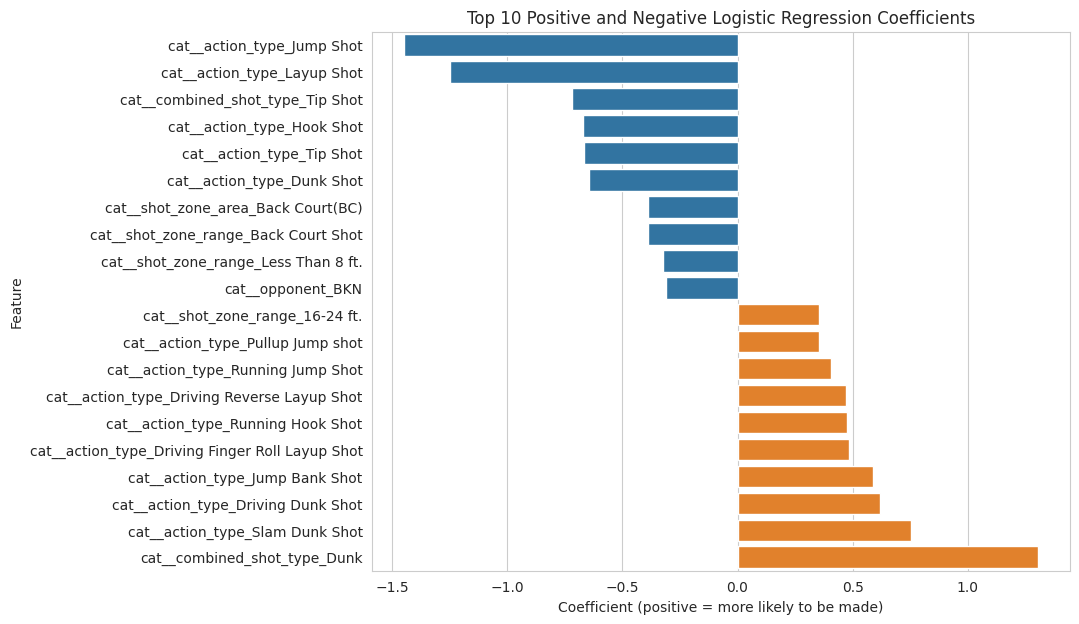

In [ ]:
# Show the features with the largest positive and negative coefficients
best_lr = lr_grid.best_estimator_

coefficients = pd.DataFrame({
    "Feature": best_lr.named_steps["preprocessor"].get_feature_names_out(),
    "Coefficient": best_lr.named_steps["model"].coef_[0]
}).sort_values("Coefficient")

top_features = pd.concat([coefficients.head(10), coefficients.tail(10)])

plt.figure(figsize=(9, 7))

sns.barplot(data=top_features, x="Coefficient", y="Feature",
            palette=["tab:blue" if c < 0 else "tab:orange" for c in top_features["Coefficient"]])

plt.title("Top 10 Positive and Negative Logistic Regression Coefficients")
plt.xlabel("Coefficient (positive = more likely to be made)")
plt.ylabel("Feature")

plt.show()

* Dunks increase the chance of a made shot the most, while plain jump shots and back court shots decrease it, which matches what we saw in the EDA.

# 10. Conclusion

* We predicted whether Kobe Bryant made a shot using KNN and Logistic Regression.
* Shot distance and shot type are the most important factors: shots close to the basket are made much more often.
* Logistic Regression was the best model with 68% accuracy, while KNN reached 66% after tuning.
* Both models predict missed shots better than made shots. Other models like Random Forest could be tried to improve the results.